# Attention Is All You Need (Vaswani et al., 2017)

Before 2017, the best translation systems read a sentence one word at a time,
with recurrent networks. This paper removed the recurrence entirely and built
the model from attention alone. The result trained faster, translated better,
and became the base of nearly every large model since.

This page follows the paper's own argument rather than repeating the full
forward pass. That pass, with every matrix printed, is in
[Autoregressive Transformer: Encoder + Decoder](/how-models-work/autoregressive-transformer-encoder-decoder/).

1. The problem: recurrence is sequential, and long paths forget
2. Scaled dot-product attention, by hand
3. Why divide by $\sqrt{d_k}$, measured
4. Multi-head attention, and what it costs
5. Masking: training a decoder on every position at once
6. The paper's numbers: complexity, model size, learning rate, results

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from hmw_motion import Scene, mix, ramp

np.random.seed(3)
np.set_printoptions(precision=4, suppress=True, linewidth=120)


def banner(title):
    print("=" * 78); print(f"  {title}"); print("=" * 78)


def step(label):
    print(); print(label); print("-" * 78)


def check(label, a, b, tol=1e-9):
    ok = np.allclose(a, b, atol=tol)
    print(f"  [{'MATCH' if ok else 'DIFFERENT'}] {label}")
    return ok


def softmax(x, axis=-1):
    z = x - x.max(axis=axis, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=axis, keepdims=True)


print("helpers ready")

helpers ready


## 1. The problem with recurrence

A recurrent network computes $h_t = f(h_{t-1}, x_t)$. Two things follow from
that one line:

* **Nothing runs in parallel along the sequence.** Step $t$ needs step $t-1$,
  so a 50-word sentence takes 50 dependent steps, however many GPU cores you
  have.
* **Distant words are far apart.** Information from word 1 reaches word 50 only
  by passing through 49 intermediate states, and each one can overwrite it.

Self-attention connects every position to every other in one step. The paper's
Table 1 states this as *maximum path length*: $O(n)$ for recurrence, $O(1)$ for
self-attention.

In [2]:
words = ["The", "cat", "that", "the", "dog", "chased", "was", "black"]
n = len(words)
sc = Scene(720, 340, dur=9.0, caption="Path from word 1 to word 8: recurrence vs self-attention",
           poster=7.6)
xs = [70 + i * 83 for i in range(n)]
for row, (y, label, col) in enumerate([(95, "recurrent", "violet"), (250, "self-attention", "cyan")]):
    sc.text(16, y - 52 if row == 0 else 150, label, size=15, fill=col, anchor="start", weight=700)
    for i, w in enumerate(words):
        sc.rect(xs[i] - 34, y - 18, 68, 36, fill="panel", stroke="grid", sw=1.5, rx=8)
        sc.text(xs[i], y, w, size=14)
# recurrent chain: arrows between neighbours, a pulse hopping along
for i in range(n - 1):
    a = sc.arrow(xs[i] + 34, 95, xs[i + 1] - 36, 95, stroke="grid", sw=2, head=8)
    a.to(0.6 + i * 0.75, 0.6 + i * 0.75 + 0.3, stroke="violet")
pulse = sc.circle(xs[0], 70, r=7, fill="violet", opacity=0)
pulse.fade_in(0.4, 0.2)
for i in range(1, n):
    pulse.to(0.6 + (i - 1) * 0.75, 0.6 + i * 0.75, cx=xs[i])
hops_r = sc.num(700, 43, 0, dec=0, pre="sequential steps: ", size=14, fill="violet", anchor="end")
for i in range(1, n):
    hops_r.set(0.6 + i * 0.75, v=i)
# attention: every word to the last one, all at once
for i in range(n - 1):
    # quadratic curve over the row, taller for longer jumps; drawn by growing
    # its points out from the source word
    x0, x1 = xs[i], xs[-1]
    hgt = 8 + (x1 - x0) * 0.085
    curve = []
    for u in np.linspace(0, 1, 24):
        curve += [(1 - u) ** 2 * x0 + 2 * u * (1 - u) * (x0 + x1) / 2 + u * u * x1,
                  (1 - u) ** 2 * 230 + 2 * u * (1 - u) * (230 - 2 * hgt) + u * u * 230]
    ln = sc.poly([x0, 230] * 24, stroke="cyan", sw=2, opacity=0.9)
    ln.to(1.2, 1.9, pts=curve, ease="out")
hops_a = sc.num(700, 150, 0, dec=0, pre="sequential steps: ", size=14, fill="cyan", anchor="end")
hops_a.set(1.7, v=1)
sc.text(360, 318, "Recurrence: 7 dependent steps, each one can overwrite the signal.  "
        "Attention: 1 step, every pair connected.", size=12, fill="muted")
sc.beat(0.0, "Does 'was' refer to the cat or the dog? The answer is 5 words back.")
sc.beat(1.2, "Self-attention links 'black' to every word directly, in a single parallel step.")
sc.beat(3.0, "The recurrent net must carry 'cat' through every state in between.")
sc

<motion scene: Path from word 1 to word 8: recurrence vs self-attention (52 elements, 9s)>

## 2. Scaled dot-product attention, by hand

The paper's central formula:

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

Read it as a **soft dictionary lookup**. Each query is compared with every key
by a dot product. The softmax turns those scores into weights that sum to 1.
The output is the weighted average of the values. A hard dictionary would return
exactly one value; attention returns a blend, which is what makes it
differentiable.

Below: four tokens, $d_k = 4$, and the output for token 0 written out in full.

In [3]:
banner("ONE QUERY, FOUR KEYS")
dk = 4
Q = np.round(np.random.randn(4, dk), 2)
K = np.round(np.random.randn(4, dk), 2)
V = np.round(np.random.randn(4, dk), 2)
q0 = Q[0]

step("Scores: q0 . k_j, then divide by sqrt(d_k) = 2")
raw = []
for j in range(4):
    terms = " + ".join(f"({a:+.2f})({b:+.2f})" for a, b in zip(q0, K[j]))
    raw.append(q0 @ K[j])
    print(f"  q0.k{j} = {terms} = {raw[-1]:+.4f}  ->  /2 = {raw[-1]/2:+.4f}")
scaled = np.array(raw) / np.sqrt(dk)

step("Softmax")
e = np.exp(scaled - scaled.max())
w_ = e / e.sum()
for j in range(4):
    print(f"  w{j} = exp({scaled[j]:+.4f} - max) / sum = {e[j]:.4f} / {e.sum():.4f} = {w_[j]:.4f}")
print(f"  weights sum to {w_.sum():.6f}")

step("Output: weighted average of the value rows")
out0 = (w_[:, None] * V).sum(0)
print(f"  out0 = " + " + ".join(f"{w_[j]:.3f}*v{j}" for j in range(4)))
print(f"       = {out0}")

full = softmax(Q @ K.T / np.sqrt(dk)) @ V
check("by-hand output for token 0 == row 0 of softmax(QK^T/sqrt(d_k)) V", out0, full[0])

  ONE QUERY, FOUR KEYS

Scores: q0 . k_j, then divide by sqrt(d_k) = 2
------------------------------------------------------------------------------
  q0.k0 = (+1.79)(-0.55) + (+0.44)(-1.55) + (+0.10)(+0.98) + (-1.86)(-1.10) = +0.4775  ->  /2 = +0.2388
  q0.k1 = (+1.79)(-1.19) + (+0.44)(-0.21) + (+0.10)(+1.49) + (-1.86)(+0.24) = -2.5199  ->  /2 = -1.2600
  q0.k2 = (+1.79)(-1.02) + (+0.44)(-0.71) + (+0.10)(+0.63) + (-1.86)(-0.16) = -1.7776  ->  /2 = -0.8888
  q0.k3 = (+1.79)(-0.77) + (+0.44)(-0.23) + (+0.10)(+0.75) + (-1.86)(+1.98) = -5.0873  ->  /2 = -2.5437

Softmax
------------------------------------------------------------------------------
  w0 = exp(+0.2388 - max) / sum = 1.0000 / 1.6091 = 0.6215
  w1 = exp(-1.2600 - max) / sum = 0.2234 / 1.6091 = 0.1388
  w2 = exp(-0.8888 - max) / sum = 0.3238 / 1.6091 = 0.2012
  w3 = exp(-2.5437 - max) / sum = 0.0619 / 1.6091 = 0.0385
  weights sum to 1.000000

Output: weighted average of the value rows
----------------------------------------

The same lookup in motion: scores are computed, the softmax squashes them into
weights, and the value rows are blended in proportion to those weights.

In [4]:
def lookup_scene():
    sc = Scene(720, 380, dur=10.0, caption="Attention as a soft lookup: score, softmax, weighted sum",
               poster=9.0)
    cols = ["cyan", "violet", "pink", "amber"]
    sc.text(40, 34, "query q0", size=14, fill="green", anchor="start", weight=700)
    for d_ in range(dk):
        sc.rect(130 + d_ * 34, 20, 30, 28, fill=mix("panel", "green", min(1, abs(q0[d_]) / 2)), rx=4)
    base_y = 200
    sc.line(40, base_y, 330, base_y, stroke="grid", sw=1.5)
    sc.text(185, 70, "score  ->  weight", size=13, fill="muted")
    bars, labels = [], []
    smax = np.abs(scaled).max()
    for j in range(4):
        x = 60 + j * 70
        bars.append(sc.rect(x, base_y, 46, 0, fill=cols[j], rx=3))
        labels.append(sc.num(x + 23, 336, 0, dec=2, size=12, fill=cols[j]))
        sc.text(x + 23, 356, f"key {j}", size=12, fill="muted")
    # phase 1: raw scaled scores grow (signed)
    for j in range(4):
        h = scaled[j] / smax * 105
        if h >= 0:
            bars[j].to(0.6, 1.8, h=h, y=base_y - h, ease="out")
        else:
            bars[j].to(0.6, 1.8, h=-h, ease="out")
        labels[j].to(0.6, 1.8, v=scaled[j])
    # phase 2: morph into softmax weights (all positive, sum to 1)
    for j in range(4):
        h = w_[j] * 125
        bars[j].to(3.0, 4.4, h=h, y=base_y - h)
        labels[j].to(3.0, 4.4, v=w_[j])
    # phase 3: value rows scaled by weight, then summed into the output
    sc.text(560, 70, "values, scaled by weight", size=13, fill="muted")
    vmax = np.abs(V).max()
    rows = []
    for j in range(4):
        y = 92 + j * 46
        sc.text(420, y + 14, f"w{j} x v{j}", size=12, fill=cols[j], anchor="end", mono=True)
        r_ = []
        for d_ in range(dk):
            c = sc.rect(430 + d_ * 52, y, 48, 30, fill=mix("panel", cols[j], abs(V[j, d_]) / vmax), rx=4,
                        opacity=0)
            c.to(4.8, 5.4, opacity=1)
            c.to(5.8, 6.8, opacity=max(0.12, w_[j]))
            r_.append(c)
        rows.append(r_)
    sc.line(430, 278, 634, 278, stroke="muted", sw=1.5, opacity=0).to(6.8, 7.2, opacity=1)
    sc.text(420, 304, "out0", size=13, fill="green", anchor="end", weight=700, opacity=0).to(7.2, 7.6, opacity=1)
    for d_ in range(dk):
        sc.rect(430 + d_ * 52, 290, 48, 30, fill=mix("panel", "green", abs(out0[d_]) / vmax), rx=4,
                opacity=0).to(7.2, 8.0, opacity=1)
        sc.num(454 + d_ * 52, 340, out0[d_], dec=2, size=12, fill="green", opacity=0).to(7.6, 8.2, opacity=1)
    sc.beat(0.0, "Compare the query with each key: dot product divided by sqrt(d_k).")
    sc.beat(3.0, "Softmax turns the scores into positive weights that add up to 1.")
    sc.beat(4.8, "Each value row is scaled by its weight; the small weights almost vanish.")
    sc.beat(7.2, "Add them up: the output is a blend, mostly of the best-matching value.")
    return sc

lookup_scene()

<motion scene: Attention as a soft lookup: score, softmax, weighted sum (50 elements, 10s)>

## 3. Why divide by $\sqrt{d_k}$

The paper's reason, in one sentence: if the components of $q$ and $k$ are
independent with mean 0 and variance 1, then $q \cdot k$ has **variance
$d_k$**. With $d_k = 64$ the scores have a standard deviation of 8, the
softmax pushes almost all its weight onto one key, and its gradient becomes
tiny. Dividing by $\sqrt{d_k}$ brings the variance back to 1.

Both halves of that claim can be measured.

  VARIANCE OF q.k GROWS WITH d_k

Empirical variance of q.k over 200,000 random pairs
------------------------------------------------------------------------------
  d_k =    4:  var(q.k) =     4.00   (theory 4)   var(q.k / sqrt(d_k)) = 0.999
  d_k =   16:  var(q.k) =    15.90   (theory 16)   var(q.k / sqrt(d_k)) = 0.994
  d_k =   64:  var(q.k) =    63.95   (theory 64)   var(q.k / sqrt(d_k)) = 0.999
  d_k =  256:  var(q.k) =   255.30   (theory 256)   var(q.k / sqrt(d_k)) = 0.997
  d_k =  512:  var(q.k) =   511.69   (theory 512)   var(q.k / sqrt(d_k)) = 0.999

What the softmax does with 10 keys, d_k = 64 (averaged over 2,000 queries)
------------------------------------------------------------------------------
  unscaled                 mean largest weight = 0.865   mean |d softmax / d scores| = 0.1608
  scaled by 1/sqrt(d_k)    mean largest weight = 0.320   mean |d softmax / d scores| = 0.3467

  Scaling makes the softmax gradient 2.2x larger on average.


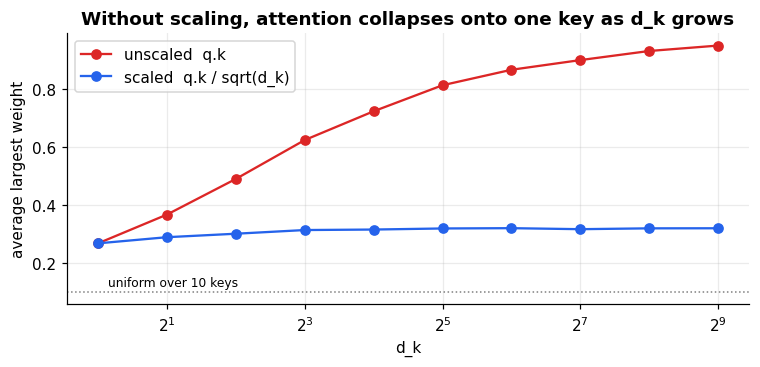

In [5]:
banner("VARIANCE OF q.k GROWS WITH d_k")
rng = np.random.default_rng(0)
step("Empirical variance of q.k over 200,000 random pairs")
for d_ in [4, 16, 64, 256, 512]:
    qq, kk = rng.standard_normal((200_000, d_)), rng.standard_normal((200_000, d_))
    dots = (qq * kk).sum(1)
    print(f"  d_k = {d_:>4}:  var(q.k) = {dots.var():8.2f}   (theory {d_})   "
          f"var(q.k / sqrt(d_k)) = {(dots/np.sqrt(d_)).var():.3f}")

step("What the softmax does with 10 keys, d_k = 64 (averaged over 2,000 queries)")
d_ = 64
res = {}
for name, scale in [("unscaled", 1.0), ("scaled by 1/sqrt(d_k)", 1 / np.sqrt(d_))]:
    maxw, gnorm = [], []
    for _ in range(2000):
        qq, kk = rng.standard_normal(d_), rng.standard_normal((10, d_))
        p = softmax(kk @ qq * scale)
        J = np.diag(p) - np.outer(p, p)            # d softmax / d scores
        maxw.append(p.max()); gnorm.append(np.linalg.norm(J))
    res[name] = (np.mean(maxw), np.mean(gnorm))
    print(f"  {name:<24} mean largest weight = {np.mean(maxw):.3f}   "
          f"mean |d softmax / d scores| = {np.mean(gnorm):.4f}")
ratio = res["scaled by 1/sqrt(d_k)"][1] / res["unscaled"][1]
print(f"\n  Scaling makes the softmax gradient {ratio:.1f}x larger on average.")

ds = np.array([1, 2, 4, 8, 16, 32, 64, 128, 256, 512])
mw_u, mw_s = [], []
for d_ in ds:
    qq, kk = rng.standard_normal((2000, d_)), rng.standard_normal((2000, 10, d_))
    sc_ = np.einsum("nkd,nd->nk", kk, qq)
    mw_u.append(softmax(sc_).max(1).mean()); mw_s.append(softmax(sc_ / np.sqrt(d_)).max(1).mean())
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(ds, mw_u, "o-", label="unscaled  q.k", color="#dc2626")
ax.plot(ds, mw_s, "o-", label="scaled  q.k / sqrt(d_k)", color="#2563eb")
ax.axhline(0.1, color="gray", ls=":", lw=1); ax.text(1.1, 0.12, "uniform over 10 keys", fontsize=8)
ax.set_xscale("log", base=2); ax.set_xlabel("d_k"); ax.set_ylabel("average largest weight")
ax.set_title("Without scaling, attention collapses onto one key as d_k grows"); ax.legend()

## 4. Multi-head attention

One attention function averages. If a word needs to look at its subject *and*
at the previous word, one set of weights has to compromise. The paper runs
$h = 8$ attention functions in parallel, each in its own $d_k = d_{model}/h = 64$
dimensional subspace, and concatenates the results:

$$\text{MultiHead}(Q,K,V) = \text{Concat}(\text{head}_1, \dots, \text{head}_h)\,W^O,
\qquad \text{head}_i = \text{Attention}(QW_i^Q, KW_i^K, VW_i^V)$$

Because each head is $h$ times narrower, eight heads cost the same as one head
of full width. The next cell checks that and counts the parameters.

In [6]:
banner("MULTI-HEAD = SAME COST AS ONE WIDE HEAD")
dm, h = 512, 8
dk_ = dm // h
one_head = 3 * dm * dm + dm * dm
multi = h * (3 * dm * dk_) + (h * dk_) * dm
print(f"  d_model = {dm}, h = {h}, d_k = d_v = {dm}/{h} = {dk_}")
print(f"  projection weights, one 512-wide head: 3*512*512 + 512*512 = {one_head:,}")
print(f"  projection weights, 8 heads of 64:     8*(3*512*64) + 512*512 = {multi:,}")
check("same number of parameters", one_head, multi)

step("And the same output, computed head by head vs with one reshaped matmul")
T_ = 5
X = rng.standard_normal((T_, dm))
Wq, Wk, Wv, Wo = (rng.standard_normal((dm, dm)) / np.sqrt(dm) for _ in range(4))
heads = []
for i in range(h):
    sl = slice(i * dk_, (i + 1) * dk_)
    q_, k_, v_ = X @ Wq[:, sl], X @ Wk[:, sl], X @ Wv[:, sl]
    heads.append(softmax(q_ @ k_.T / np.sqrt(dk_)) @ v_)
loop_out = np.concatenate(heads, 1) @ Wo
Qh = (X @ Wq).reshape(T_, h, dk_).transpose(1, 0, 2)
Kh = (X @ Wk).reshape(T_, h, dk_).transpose(1, 0, 2)
Vh = (X @ Wv).reshape(T_, h, dk_).transpose(1, 0, 2)
batched = (softmax(Qh @ Kh.transpose(0, 2, 1) / np.sqrt(dk_)) @ Vh).transpose(1, 0, 2).reshape(T_, dm) @ Wo
check("8 separate heads == one batched reshape", loop_out, batched)

  MULTI-HEAD = SAME COST AS ONE WIDE HEAD
  d_model = 512, h = 8, d_k = d_v = 512/8 = 64
  projection weights, one 512-wide head: 3*512*512 + 512*512 = 1,048,576
  projection weights, 8 heads of 64:     8*(3*512*64) + 512*512 = 1,048,576
  [MATCH] same number of parameters

And the same output, computed head by head vs with one reshaped matmul
------------------------------------------------------------------------------
  [MATCH] 8 separate heads == one batched reshape


## 5. Masking: train on every position at once

The decoder generates left to right, so position $i$ must not see positions
after it. The paper enforces this inside the softmax by setting those scores
to $-\infty$. Their weight becomes exactly zero.

This is what makes training fast. One forward pass over a 50-token target gives
50 next-token predictions at once, each seeing only its own past. A recurrent
decoder has to produce them one after another.

In [7]:
banner("CAUSAL MASK")
T_ = 5
S = rng.standard_normal((T_, T_))
mask = np.triu(np.ones((T_, T_), bool), 1)
A = softmax(np.where(mask, -np.inf, S))
print("  attention weights (row = query position, column = key position):")
print(A)
check("every row sums to 1", A.sum(1), np.ones(T_))
check("every weight above the diagonal is exactly 0", A[mask], 0.0, tol=0)

step("Changing a FUTURE token does not change an earlier output")
Xs = rng.standard_normal((T_, 8)); Vs = rng.standard_normal((8, 8))
def causal_out(Xin):
    Sc = Xin @ Xin.T
    return softmax(np.where(mask, -np.inf, Sc)) @ (Xin @ Vs)
o1 = causal_out(Xs); X2 = Xs.copy(); X2[4] += 5.0
o2 = causal_out(X2)
check("outputs 0..3 unchanged after editing token 4", o1[:4], o2[:4])
print(f"  output 4 changed by {np.abs(o1[4]-o2[4]).max():.3f}, as it should")

  CAUSAL MASK
  attention weights (row = query position, column = key position):
[[1.     0.     0.     0.     0.    ]
 [0.2201 0.7799 0.     0.     0.    ]
 [0.0784 0.6775 0.2441 0.     0.    ]
 [0.4004 0.4761 0.0768 0.0467 0.    ]
 [0.2683 0.2794 0.2248 0.1382 0.0892]]
  [MATCH] every row sums to 1
  [MATCH] every weight above the diagonal is exactly 0

Changing a FUTURE token does not change an earlier output
------------------------------------------------------------------------------
  [MATCH] outputs 0..3 unchanged after editing token 4
  output 4 changed by 27.511, as it should


## 6. The paper's numbers

**Cost per layer** (the paper's Table 1, with $n$ the sequence length and $d$ the
width):

| Layer | Work per layer | Sequential steps | Longest path |
|---|---|---|---|
| Self-attention | $O(n^2 d)$ | $O(1)$ | $O(1)$ |
| Recurrent | $O(n d^2)$ | $O(n)$ | $O(n)$ |
| Convolution (kernel $k$) | $O(k n d^2)$ | $O(1)$ | $O(\log_k n)$ |

Self-attention is cheaper than recurrence whenever $n < d$. That held for
sentence-level translation, with $n$ in the tens and $d = 512$. The quadratic
term is also why long-context models later needed so much engineering.

In [8]:
banner("WHEN IS SELF-ATTENTION CHEAPER?  (d = 512)")
d_ = 512
for n_ in [25, 50, 100, 512, 2048, 32768]:
    att, rec = n_ * n_ * d_, n_ * d_ * d_
    print(f"  n = {n_:>6}:  n^2 d = {att:>16,}   n d^2 = {rec:>16,}   "
          f"{'attention cheaper' if att < rec else 'recurrence cheaper' if att > rec else 'equal'}")

  WHEN IS SELF-ATTENTION CHEAPER?  (d = 512)
  n =     25:  n^2 d =          320,000   n d^2 =        6,553,600   attention cheaper
  n =     50:  n^2 d =        1,280,000   n d^2 =       13,107,200   attention cheaper
  n =    100:  n^2 d =        5,120,000   n d^2 =       26,214,400   attention cheaper
  n =    512:  n^2 d =      134,217,728   n d^2 =      134,217,728   equal
  n =   2048:  n^2 d =    2,147,483,648   n d^2 =      536,870,912   recurrence cheaper
  n =  32768:  n^2 d =  549,755,813,888   n d^2 =    8,589,934,592   recurrence cheaper


**Model size.** The base model has $N = 6$ encoder and 6 decoder layers,
$d_{model} = 512$, $d_{ff} = 2048$ and $h = 8$. The big model uses 1024, 4096
and 16. The paper reports 65M and 213M parameters. Counting layer by layer,
with a shared ~37,000-token BPE vocabulary, gets close to both.

In [9]:
banner("COUNTING THE PARAMETERS")
def count(dm, dff, N=6, vocab=37000):
    attn = 4 * dm * dm + 4 * dm
    ffn = 2 * dm * dff + dff + dm
    ln = 2 * dm
    enc = N * (attn + ffn + 2 * ln)
    dec = N * (2 * attn + ffn + 3 * ln)
    emb = vocab * dm               # shared by encoder input, decoder input, output
    return enc, dec, emb, enc + dec + emb
for name, dm, dff, rep in [("base", 512, 2048, 65e6), ("big", 1024, 4096, 213e6)]:
    enc, dec, emb, tot = count(dm, dff)
    print(f"  {name:<5} encoder {enc/1e6:6.1f}M + decoder {dec/1e6:6.1f}M + embeddings {emb/1e6:5.1f}M"
          f" = {tot/1e6:6.1f}M   (paper: {rep/1e6:.0f}M, off by {100*(tot-rep)/rep:+.1f}%)")
print("\n  The gap is the vocabulary size, which the paper gives only as about 37,000.")

  COUNTING THE PARAMETERS
  base  encoder   18.9M + decoder   25.2M + embeddings  18.9M =   63.1M   (paper: 65M, off by -3.0%)
  big   encoder   75.6M + decoder  100.8M + embeddings  37.9M =  214.2M   (paper: 213M, off by +0.6%)

  The gap is the vocabulary size, which the paper gives only as about 37,000.


**Learning rate.** The paper increases the learning rate linearly for 4,000
warm-up steps, then decays it with the inverse square root of the step number:

$$lr = d_{model}^{-0.5}\cdot\min\left(step^{-0.5},\ step\cdot warmup^{-1.5}\right)$$

Warm-up has since become standard for transformers, because large updates in
the first steps, made while the Adam statistics are still noisy, can destabilise
training.

  THE WARM-UP SCHEDULE
  peak at step 4,000: lr = 0.000699
  check: 512^-0.5 * 4000^-0.5 = 0.000699
  at step 100,000 (end of base training): lr = 0.000140


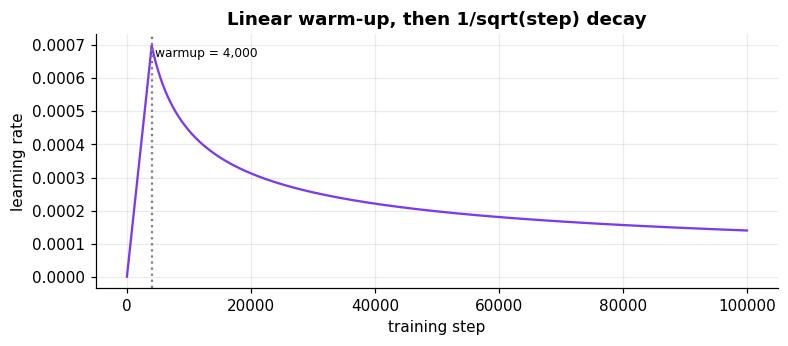

In [10]:
banner("THE WARM-UP SCHEDULE")
steps = np.arange(1, 100_001)
lr = 512 ** -0.5 * np.minimum(steps ** -0.5, steps * 4000 ** -1.5)
print(f"  peak at step {steps[lr.argmax()]:,}: lr = {lr.max():.6f}")
print(f"  check: 512^-0.5 * 4000^-0.5 = {512**-0.5 * 4000**-0.5:.6f}")
print(f"  at step 100,000 (end of base training): lr = {lr[-1]:.6f}")
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(steps, lr, color="#7c3aed")
ax.axvline(4000, ls=":", color="gray"); ax.text(4600, lr.max() * 0.95, "warmup = 4,000", fontsize=8)
ax.set_xlabel("training step"); ax.set_ylabel("learning rate")
ax.set_title("Linear warm-up, then 1/sqrt(step) decay")

**Results.** On WMT 2014 English to German, the big model reached
**28.4 BLEU**, more than 2 BLEU above the best earlier results, ensembles
included. On English to French it reached **41.8 BLEU**. The base model trained
for 100,000 steps, about 12 hours on 8 P100 GPUs. The big model trained for
300,000 steps, about 3.5 days. That was a fraction of the training cost of the
systems it beat.

## Summary

* Recurrence forces sequential computation and long paths between distant
  words. Self-attention has neither.
* Attention is a soft dictionary lookup: dot-product scores, a softmax, and a
  weighted average of values.
* The $\sqrt{d_k}$ scaling keeps score variance at 1. Without it the softmax
  saturates and its gradient shrinks; measured here, about 2× smaller at
  $d_k = 64$.
* Multi-head attention costs the same as one wide head and lets different heads
  attend to different things.
* Masking lets a decoder train on every position in parallel.
* What came next: GPT kept only the decoder, BERT kept only the encoder, and ViT
  applied the encoder to image patches. Each has its own page in this section.